# Projeto 2 - Task 1: Construção das séries temporais, análise exploratória e protocolo de previsão

**Objetivo do projeto:** prever o número de sessões de carregamento de VE que começam em cada uma das próximas 24 horas, ao nível da rede e de cada distrito.

## Índice

| Secção | Subsecção |
|---|---|
| **1. Preparação dos dados** | 1.1 Setup e carregamento |
| | 1.2 Auditoria da qualidade dos dados |
| | 1.3 Construção das séries horárias |
| **2. Análise exploratória** | 2.1 Evolução e tendência |
| | 2.2 Sazonalidade diária e semanal |
| | 2.3 Decomposição STL |
| | 2.4 Autocorrelação (ACF / PACF) |
| | 2.5 Diferenças entre distritos |
| | 2.6 Decisões para a formulação e avaliação |
| **3. Formulação operacional** | 3.1 Formulação do problema |
| | 3.2 Estratégia multi-step |
| | 3.3 Preditores e prevenção de leakage |
| **4. Protocolo de avaliação** | 4.1 Divisão temporal (treino / validação / teste) |
| | 4.2 Métricas (MAE, RMSE, MASE) |
| | 4.3 Baselines |
| **5. Síntese final** | — |

## 1. Preparação dos dados

### 1.1 Setup e carregamento

**Conceito: série temporal**
Uma série temporal é uma sequência de observações ordenadas no tempo (y₁, y₂, …, yₜ).
Ao contrário do Projeto 1, aqui **a ordem das linhas é informação**: não podemos alterar a ordem dos dados.

O nosso dataset **ainda não é uma série temporal**: cada linha é **uma transação**.
Vamos ter de **agregar** as transações por hora para obter a série.

In [1]:
# Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 30)

In [2]:
# O ficheiro tem caracteres chineses no cabeçalho da temperatura -> encoding latin-1
df = pd.read_csv('data/Charging_Data.csv', encoding='latin-1')

# Limpar os nomes das colunas e renomear a da temperatura (vem com caracteres estranhos)
df.columns = df.columns.str.strip()
df = df.rename(columns={df.columns[13]: 'Temperature(C)'})

# As datas vêm com um TAB no fim ("2020-12-31 23:35:55\t") -> remover antes de converter
date_cols = ['Order creation time', 'Start Time', 'End Time', 'Payment time']
for c in date_cols:
    df[c] = pd.to_datetime(df[c].astype(str).str.strip(), errors='coerce')

print(df.shape)
df.head()

(441077, 24)


,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,Start Time,End Time,Payment time,Temperature(C),Relative Humidity(%),Precipitation(mm),end_cause,is_full_charge,is_user_stop,is_nonsystem_fault,is_system_issue,is_EV_fault,is_other_fault,is_abnormal
0,1,1,Tourist Attraction,Nanhu,2020-12-31 23:35:55,6.24,2.60,3.74,6.34,6.34,2020-12-31 23:35:43,2020-12-31 23:48:08,2020-12-31 23:48:27,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
1,2,2,Tourist Attraction,Nanhu,2020-12-31 23:35:17,0.62,0.26,0.37,0.63,0.63,2020-12-31 23:35:19,2020-12-31 23:38:00,2020-12-31 23:38:04,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
2,3,3,Tourist Attraction,Nanhu,2020-12-31 22:01:34,28.01,11.66,16.81,28.47,28.47,2020-12-31 22:00:05,2020-12-31 22:39:38,2020-12-31 22:41:14,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
3,4,2,Tourist Attraction,Nanhu,2020-12-31 22:21:37,5.20,2.17,3.12,5.29,5.29,2020-12-31 22:21:38,2020-12-31 22:34:08,2020-12-31 22:34:12,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
4,5,1,Tourist Attraction,Nanhu,2020-12-31 22:10:30,4.58,1.91,2.75,4.66,4.66,2020-12-31 22:10:31,2020-12-31 22:20:10,2020-12-31 22:20:16,-3.2,45,0.0,Charging ends normally,1,0,0,0,0,0,0


### 1.2 Auditoria da qualidade dos dados

O enunciado pede para **distinguir problemas de qualidade de variações legítimas da procura**:

| Tipo | Exemplo | O que fazer |
|---|---|---|
| Problema de qualidade | data inválida, fim < início, duplicados, falha no registo | corrigir / remover |
| Variação legítima | poucas sessões de madrugada, quebra num feriado | **manter**, porque é isso que queremos prever |

Vamos verificar:
1. Datas inválidas e sessões com fim antes do início
2. Linhas duplicadas
3. **Cobertura temporal**: de quando a quando há dados e se há meses "estranhos"

**Nota:** o ficheiro original **não está ordenado por data** (as primeiras linhas são de dezembro de 2020). Isto não afeta a análise, porque as transações vão ser agregadas por hora.

In [3]:
# 1) Datas inválidas e coerência temporal
print('Datas inválidas (NaT):')
print(df[date_cols].isna().sum(), '\n')

n_fim_antes = (df['End Time'] < df['Start Time']).sum()
print('Sessões com fim antes do início:', n_fim_antes)

# 2) Duplicados
print('Linhas duplicadas:', df.duplicated().sum())

# 3) Cobertura temporal
print('\nPrimeira sessão:', df['Start Time'].min())
print('Última sessão:  ', df['Start Time'].max())

Datas inválidas (NaT):
Order creation time    0
Start Time             0
End Time               0
Payment time           0
dtype: int64 

Sessões com fim antes do início: 0
Linhas duplicadas: 0

Primeira sessão: 2019-12-31 21:27:03
Última sessão:   2021-12-31 23:52:14


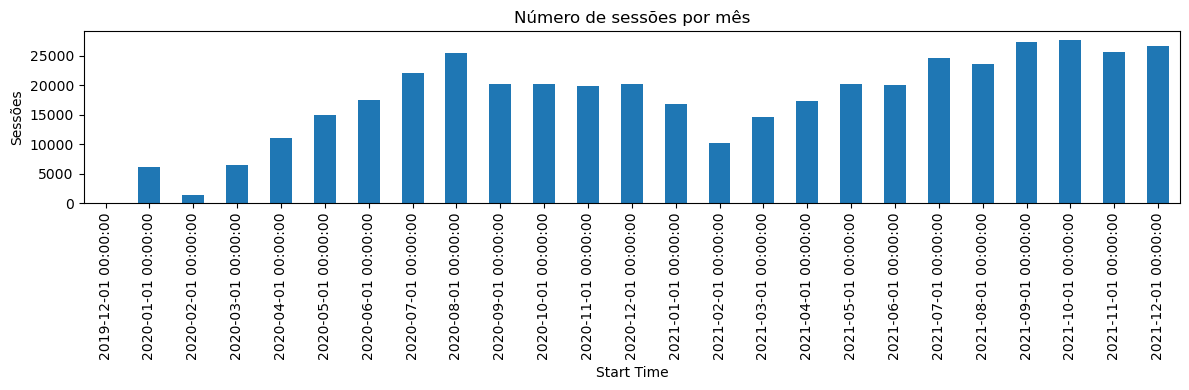

Start Time
2019-12-01       17
2020-01-01     6217
2020-02-01     1391
2020-03-01     6392
2020-04-01    11136
2020-05-01    15033
2020-06-01    17513
2020-07-01    22032
2020-08-01    25562
2020-09-01    20231
2020-10-01    20252
2020-11-01    19925
2020-12-01    20187
2021-01-01    16915
2021-02-01    10283
2021-03-01    14599
2021-04-01    17307
2021-05-01    20209
2021-06-01    20026
2021-07-01    24703
2021-08-01    23692
2021-09-01    27374
2021-10-01    27794
2021-11-01    25669
2021-12-01    26618
Freq: MS, dtype: int64

In [4]:
# Nº de sessões por mês -> ver se há meses incompletos ou anómalos
sessoes_mes = df.set_index('Start Time').resample('MS').size()

sessoes_mes.plot(kind='bar', figsize=(12, 4), color='tab:blue')
plt.title('Número de sessões por mês')
plt.ylabel('Sessões')
plt.tight_layout()
plt.show()

sessoes_mes

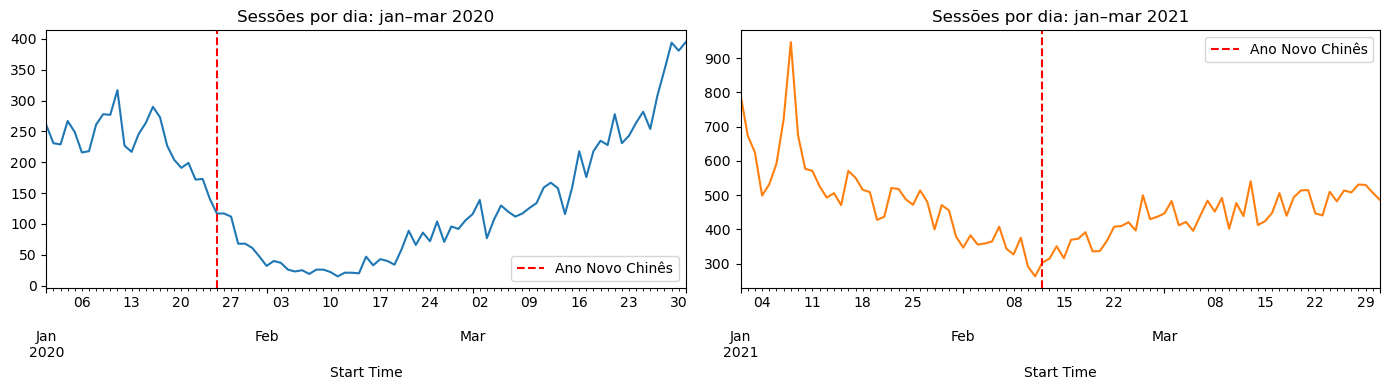

Start Time
2020-01    200.5
2020-02     48.0
2020-03    206.2
2020-04    371.2
2020-05    484.9
2020-06    583.8
2020-07    710.7
2020-08    824.6
2020-09    674.4
2020-10    653.3
2020-11    664.2
2020-12    651.2
2021-01    545.6
2021-02    367.2
2021-03    470.9
2021-04    576.9
2021-05    651.9
2021-06    667.5
2021-07    796.9
2021-08    764.3
2021-09    912.5
2021-10    896.6
2021-11    855.6
2021-12    858.6
dtype: float64

In [5]:
# Validar H2: sessões por DIA à volta do Ano Novo Chinês
# Ano Novo Chinês: 25/01/2020 e 12/02/2021
sessoes_dia = df.set_index('Start Time').resample('D').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)

sessoes_dia['2020-01-01':'2020-03-31'].plot(ax=axes[0], color='tab:blue')
axes[0].axvline(pd.Timestamp('2020-01-25'), color='red', linestyle='--', label='Ano Novo Chinês')
axes[0].set_title('Sessões por dia: jan–mar 2020')
axes[0].legend()

sessoes_dia['2021-01-01':'2021-03-31'].plot(ax=axes[1], color='tab:orange')
axes[1].axvline(pd.Timestamp('2021-02-12'), color='red', linestyle='--', label='Ano Novo Chinês')
axes[1].set_title('Sessões por dia: jan–mar 2021')
axes[1].legend()

plt.tight_layout()
plt.show()

# Média diária por mês (corrige o efeito de fevereiro ter menos dias)
media_diaria = sessoes_dia['2020-01-01':].resample('MS').mean().round(1)
media_diaria.index = media_diaria.index.strftime('%Y-%m')
media_diaria

**Hipóteses e validação:**

- **H1 — Dezembro de 2019 é um mês incompleto: Confirmada.**
  A primeira sessão ocorre a 31/12/2019 às 21:27 (apenas 17 sessões). É um problema de **cobertura** e não procura real.
  **Decisão:** a série começa a **01/01/2020**.

- **H2 — As quebras de fevereiro são variações legítimas: Confirmada, com nuances.**
  - **2020:** quebra longa (de meados de janeiro ao fim de março), com mínimo de cerca de 20 sessões/dia. Compatível com o Ano Novo Chinês (25/01) e as restrições da COVID-19. É procura real, mas **atípica**.
  - **2021:** quebra moderada e concentrada à volta do Ano Novo Chinês (12/02). A média diária de fevereiro (367) é inferior à de janeiro (546), o que confirma que o efeito não se deve apenas a fevereiro ter menos dias.

  **Decisão:** não remover estes períodos (não são erros), mas **assinalar jan–mar 2020 como período atípico**, a considerar na escolha do período de treino (secção 2.6).

**Outras observações:**
- A procura tem uma **tendência crescente forte**: a média diária passa de ~200 (jan/2020) para ~860 (dez/2021).
- Pico isolado a **08/01/2021** (~950 sessões), a analisar na secção 2.
- Não foram encontradas datas inválidas, sessões com fim antes do início nem linhas duplicadas.

### 1.3 Construção das séries horárias

**Conceito: frequência e granularidade (slide 11)**
- **Frequência:** de quanto em quanto tempo temos um valor → **horária**
- **Granularidade:** a que nível agregamos → **rede** (total) e **distrito** (3 séries)

**Como construir:**
1. Arredondar o `Start Time` para baixo, à hora (`floor('h')`), porque o alvo são sessões que **começam** em cada hora
2. Contar as sessões por hora
3. Criar um índice com **todas** as horas do período. As horas sem nenhuma sessão não aparecem na contagem, por isso temos de as acrescentar com valor **0**

**Atenção:** uma hora sem sessões pode ser **procura zero real** (madrugada) ou **falha de registo**. Vamos analisar isso a seguir.

**Período:** de 01/01/2020 00:00 a 31/12/2021 23:00 (decisão da H1).

In [6]:
df['hora'] = df['Start Time'].dt.floor('h')

# Índice completo: todas as horas entre o início e o fim do período
idx = pd.date_range('2020-01-01 00:00', '2021-12-31 23:00', freq='h')

# Série da REDE
rede = df.groupby('hora').size().reindex(idx, fill_value=0)
rede.name = 'Rede'

# Séries por DISTRITO (uma coluna por distrito)
distritos = (df.groupby(['hora', 'District Name']).size()
               .unstack(fill_value=0)
               .reindex(idx, fill_value=0))

series = pd.concat([rede, distritos], axis=1)
series.index.name = 'hora'

print('Nº de horas:', len(series))
print('Confirmação (soma dos distritos = rede):',
      (series[distritos.columns].sum(axis=1) == series['Rede']).all())
series.head()

Nº de horas: 17544
Confirmação (soma dos distritos = rede): True


,Rede,Nanhu,Tongxiang,Xiuzhou
hora,,,,
2020-01-01 00:00:00,16,0,11,5
2020-01-01 01:00:00,3,2,1,0
2020-01-01 02:00:00,1,0,1,0
2020-01-01 03:00:00,5,0,4,1
2020-01-01 04:00:00,4,0,2,2


In [7]:
# Total de sessões na série (as 17 sessões de dez/2019 ficaram de fora)
print('Total de sessões nas séries:', series['Rede'].sum(), '\n')

# Horas com ZERO sessões em cada série
zeros = (series == 0).sum()
print('Horas com 0 sessões:')
pd.DataFrame({'n_horas': zeros, '% do total': (zeros / len(series) * 100).round(2)})

Total de sessões nas séries: 441060 

Horas com 0 sessões:


,n_horas,% do total
Rede,480,2.74
Nanhu,3582,20.42
Tongxiang,1012,5.77
Xiuzhou,1741,9.92


In [8]:
# Sequências de zeros consecutivos na REDE
# Zeros isolados de madrugada -> normal. Muitas horas seguidas a zero -> suspeito.
z = series['Rede'] == 0
grupo = (z != z.shift()).cumsum()

blocos = (series.loc[z, 'Rede']
          .groupby(grupo[z])
          .agg(inicio=lambda s: s.index.min(), n_horas='size')
          .sort_values('n_horas', ascending=False))

# Em que meses e a que horas do dia aparecem os zeros da rede?
zeros_rede = series.index[z]
print('Zeros da rede por mês:')
print(zeros_rede.to_period('M').value_counts().sort_index().to_string(), '\n')
print('Zeros da rede por hora do dia:')
print(zeros_rede.hour.value_counts().sort_index().to_dict(), '\n')

print('Os 10 blocos de zeros mais longos:')
blocos.head(10)

Zeros da rede por mês:
hora
2020-01     60
2020-02    277
2020-03     89
2020-04     11
2020-05      3
2020-10      1
2020-11      1
2020-12      3
2021-01      5
2021-02     13
2021-03      7
2021-04      2
2021-05      1
2021-06      4
2021-07      1
2021-08      1
2021-12      1
Freq: M 

Zeros da rede por hora do dia:
{0: 22, 1: 34, 2: 47, 3: 55, 4: 65, 5: 66, 6: 52, 7: 34, 8: 15, 9: 15, 10: 9, 11: 6, 12: 5, 13: 3, 14: 3, 15: 2, 16: 3, 17: 4, 18: 8, 19: 7, 20: 6, 21: 3, 22: 6, 23: 10} 

Os 10 blocos de zeros mais longos:


,inicio,n_horas
Rede,,
192,2020-02-13 23:00:00,12
198,2020-02-15 00:00:00,10
164,2020-02-09 22:00:00,10
172,2020-02-11 01:00:00,10
158,2020-02-09 01:00:00,9
102,2020-02-04 02:00:00,9
206,2020-02-16 23:00:00,8
230,2020-02-20 00:00:00,8
202,2020-02-16 00:00:00,8


In [9]:
# Zeros da rede FORA do período atípico (a partir de abril de 2020)
zeros_normais = zeros_rede[zeros_rede >= '2020-04-01']

print('Nº de zeros a partir de abr/2020:', len(zeros_normais))
print('Por hora do dia:', zeros_normais.hour.value_counts().sort_index().to_dict())

Nº de zeros a partir de abr/2020: 54
Por hora do dia: {2: 7, 3: 6, 4: 12, 5: 20, 6: 7, 7: 2}


**Hipóteses e validação:**

- **H3 - Séries com menor volume têm mais horas a zero: Confirmada.**
  Rede: 2,74% | Tongxiang: 5,77% | Xiuzhou: 9,92% | Nanhu: 20,42%.
  A ordem coincide com o volume de sessões de cada distrito. Em **Nanhu**, 1 em cada 5 horas não tem sessões, o que torna esta série mais **irregular** e, à partida, mais difícil de prever.

- **H4 - Os zeros da rede são procura real e não falhas de registo: Confirmada.**
  - 426 dos 480 zeros (~89%) ocorrem em **jan–mar 2020** (período atípico, ver H2);
  - fora desse período existem apenas 54 zeros, **todos entre as 2h e as 7h** (madrugada);
  - o bloco mais longo de zeros tem **12 horas** (fev/2020); **não existe nenhum dia inteiro sem sessões**.

**Decisão:** os zeros são mantidos como **procura zero real** (sem imputação). Não foram detetados intervalos em falta na série.